In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import c1844 as c

print('code [[18, 4, 4]], k =', c.N_DATA - c.gf2_rank(c.hx) - c.gf2_rank(c.hz))
print('lx weights', c.lx.sum(1), 'lz weights', c.lz.sum(1))
print('(lx @ lz.T) % 2 =\n', (c.lx @ c.lz.T) % 2)
print('schedule valid:', c.checkvalidschedule(c.defaultzschedule), c.checkvalidschedule(c.defaultxschedule))
c.defaultzschedule, c.defaultxschedule

code [[18, 4, 4]], k = 4
lx weights [6 6 4 6] lz weights [6 6 4 4]
(lx @ lz.T) % 2 =
 [[1 0 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]]
schedule valid: True True


(array([[4, 0, 3, 5, 0, 0, 0, 0, 0, 6, 2, 0, 0, 0, 0, 1, 0, 0],
        [3, 4, 0, 0, 5, 0, 0, 0, 0, 0, 6, 2, 0, 0, 0, 0, 1, 0],
        [0, 3, 4, 0, 0, 5, 0, 0, 0, 2, 0, 6, 0, 0, 0, 0, 0, 1],
        [0, 0, 0, 4, 0, 3, 5, 0, 0, 1, 0, 0, 6, 2, 0, 0, 0, 0],
        [0, 0, 0, 3, 4, 0, 0, 5, 0, 0, 1, 0, 0, 6, 2, 0, 0, 0],
        [0, 0, 0, 0, 3, 4, 0, 0, 5, 0, 0, 1, 2, 0, 6, 0, 0, 0],
        [5, 0, 0, 0, 0, 0, 4, 0, 3, 0, 0, 0, 1, 0, 0, 6, 2, 0],
        [0, 5, 0, 0, 0, 0, 3, 4, 0, 0, 0, 0, 0, 1, 0, 0, 6, 2],
        [0, 0, 5, 0, 0, 0, 0, 3, 4, 0, 0, 0, 0, 0, 1, 2, 0, 6]]),
 array([[1, 0, 6, 5, 0, 0, 0, 0, 0, 2, 3, 0, 0, 0, 0, 4, 0, 0],
        [6, 1, 0, 0, 5, 0, 0, 0, 0, 0, 2, 3, 0, 0, 0, 0, 4, 0],
        [0, 6, 1, 0, 0, 5, 0, 0, 0, 3, 0, 2, 0, 0, 0, 0, 0, 4],
        [0, 0, 0, 1, 0, 6, 5, 0, 0, 4, 0, 0, 2, 3, 0, 0, 0, 0],
        [0, 0, 0, 6, 1, 0, 0, 5, 0, 0, 4, 0, 0, 2, 3, 0, 0, 0],
        [0, 0, 0, 0, 6, 1, 0, 0, 5, 0, 0, 4, 3, 0, 2, 0, 0, 0],
        [5, 0, 0, 0, 0, 0, 1, 0, 6, 0,

In [2]:
# Zero-noise sanity check
cb = c.c1844scheduleable(er=0, nrounds=1)
sample = cb.get_circuit().compile_sampler().sample(5000)
sl = c.defaultzschedule.shape[0] + c.defaultxschedule.shape[0]
totalshots, totalerrors, survived, survivederrors = c.sim_analysis(sample, sl, 1, c.lx)
print(totalshots, survived, survivederrors, totalerrors)
assert survived == totalshots and all(e == 0 for e in survivederrors)

5000 5000 [0, 0, 0, 0] [0, 0, 0, 0]


In [4]:
nrounds_list = [1, 2, 4]
ers = [1e-4, 1e-3, 1e-2]
nshots = 100_000
sl = c.defaultzschedule.shape[0] + c.defaultxschedule.shape[0]

rows = []
for n in tqdm(nrounds_list):
    for er in ers:
        cb = c.c1844scheduleable(er=er, nrounds=n)
        sample = cb.get_circuit().compile_sampler().sample(nshots)
        totalshots, totalerrors, survived, survivederrors = c.sim_analysis(sample, sl, n, c.lx)
        post = [e / survived if survived else np.nan for e in survivederrors]
        raw = [e / totalshots for e in totalerrors]
        rows.append(dict(nrounds=n, er=er, survived=survived, post=post, raw=raw))
        print(f'n={n} er={er}: survived {survived}/{totalshots}, postsel LER={post}')
rows

 33%|███▎      | 1/3 [00:00<00:00,  8.07it/s]

n=1 er=0.0001: survived 95969/100000, postsel LER=[0.0, 0.0, 0.0, 0.0]
n=1 er=0.001: survived 65448/100000, postsel LER=[0.0, 0.0, 0.0, 0.0]
n=1 er=0.01: survived 1369/100000, postsel LER=[0.0, 0.0, 0.0, 0.0]
n=2 er=0.0001: survived 91908/100000, postsel LER=[0.0, 0.0, 0.0, 0.0]
n=2 er=0.001: survived 43113/100000, postsel LER=[0.0, 0.0, 0.0, 0.0]


 67%|██████▋   | 2/3 [00:00<00:00,  7.03it/s]

n=2 er=0.01: survived 18/100000, postsel LER=[0.0, 0.0, 0.0, 0.0]
n=4 er=0.0001: survived 84361/100000, postsel LER=[0.0, 0.0, 0.0, 0.0]
n=4 er=0.001: survived 18273/100000, postsel LER=[0.0, 0.0, 0.0, 0.0]


100%|██████████| 3/3 [00:00<00:00,  5.85it/s]

n=4 er=0.01: survived 0/100000, postsel LER=[nan, nan, nan, nan]


[{'nrounds': 1,
  'er': 0.0001,
  'survived': 95969,
  'post': [0.0, 0.0, 0.0, 0.0],
  'raw': [0.00726, 0.00721, 0.0051, 0.00744]},
 {'nrounds': 1,
  'er': 0.001,
  'survived': 65448,
  'post': [0.0, 0.0, 0.0, 0.0],
  'raw': [0.07198, 0.07228, 0.0524, 0.07436]},
 {'nrounds': 1,
  'er': 0.01,
  'survived': 1369,
  'post': [0.0, 0.0, 0.0, 0.0],
  'raw': [0.39532, 0.39342, 0.33583, 0.40375]},
 {'nrounds': 2,
  'er': 0.0001,
  'survived': 91908,
  'post': [0.0, 0.0, 0.0, 0.0],
  'raw': [0.01484, 0.0147, 0.01052, 0.01593]},
 {'nrounds': 2,
  'er': 0.001,
  'survived': 43113,
  'post': [0.0, 0.0, 0.0, 0.0],
  'raw': [0.13217, 0.1311, 0.09832, 0.13648]},
 {'nrounds': 2,
  'er': 0.01,
  'survived': 18,
  'post': [0.0, 0.0, 0.0, 0.0],
  'raw': [0.47913, 0.47685, 0.44277, 0.48051]},
 {'nrounds': 4,
  'er': 0.0001,
  'survived': 84361,
  'post': [0.0, 0.0, 0.0, 0.0],
  'raw': [0.02979, 0.02958, 0.02166, 0.03114]},
 {'nrounds': 4,
  'er': 0.001,
  'survived': 18273,
  'post': [0.0, 0.0, 0.0, 0.0],

/tmp/ipykernel_866024/3937599326.py:5: RuntimeWarning: Mean of empty slice
  ys = [np.nanmean(r['post']) for r in rows if r['nrounds'] == n]
/tmp/ipykernel_866024/3937599326.py:8: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_yscale('log')


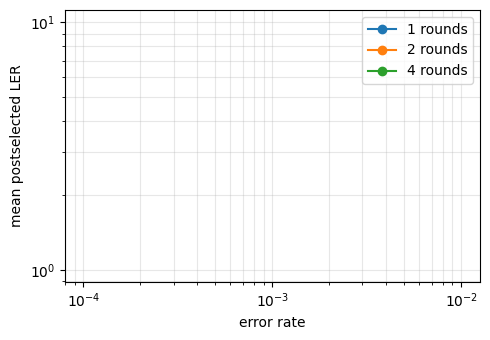

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.5))
for n in nrounds_list:
    xs = [r['er'] for r in rows if r['nrounds'] == n]
    # mean postselected LER over the 4 logicals
    ys = [np.nanmean(r['post']) for r in rows if r['nrounds'] == n]
    ax.plot(xs, ys, 'o-', label=f'{n} rounds')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('error rate')
ax.set_ylabel('mean postselected LER')
ax.legend()
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Optional: inspect Stim diagram for the default schedule
print(c.c1844scheduleable(0.01, 1).get_circuit().diagram())

      /------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------\ /---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------\ /---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------\ /---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------\ /------------------------------------------------------------------------------------------------------------------------------------------------------